# Fashion-MNIST · Evaluación y errores

Ejecuta las tres celdas de código en orden. Consulta la [metodología](../docs/metodologia.md). Los comentarios y cifras se calculan al ejecutar; las alertas no certifican calidad del modelo.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("fashion_mnist_classification")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from fashion_mnist_classification.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Clasificación visual de prendas: evaluacion

En el **test oficial de 10,000 imágenes**, la MLP obtiene **accuracy 85.18%** y **F1 macro 0.8536**: **supera** el F1 macro del baseline (**0.8040**). La clase con menor recall es **Abrigo: 68.80%**. Hay **1,482 errores**. La confusión más frecuente es **Jersey → Camisa (171 casos)**. Estos resultados describen un benchmark de prendas pequeñas en gris; no acreditan desempeño con fotografías reales. Test se usa para evaluación y diagnóstico, no para elegir alpha ni iteraciones.


,baseline,modelo
casos,10000.000000,10000.000000
accuracy,0.810100,0.851800
f1_macro,0.803985,0.853632


,precision,recall,f1-score,support
Camiseta/top,0.794004,0.8210,0.807276,1000.0000
Pantalón,0.982420,0.9500,0.965938,1000.0000
Jersey,0.765935,0.7330,0.749106,1000.0000
Vestido,0.893204,0.8280,0.859367,1000.0000
Abrigo,0.804678,0.6880,0.741779,1000.0000
Sandalia,0.940179,0.9430,0.941588,1000.0000
Camisa,0.580336,0.7260,0.645047,1000.0000
Zapatilla,0.928642,0.9370,0.932802,1000.0000
Bolso,0.948052,0.9490,0.948526,1000.0000
Botín,0.946787,0.9430,0.944890,1000.0000


,casos,real,prediccion
0,171,Jersey,Camisa
1,167,Abrigo,Camisa
2,133,Camisa,Camiseta/top
3,128,Camiseta/top,Camisa
4,108,Abrigo,Jersey


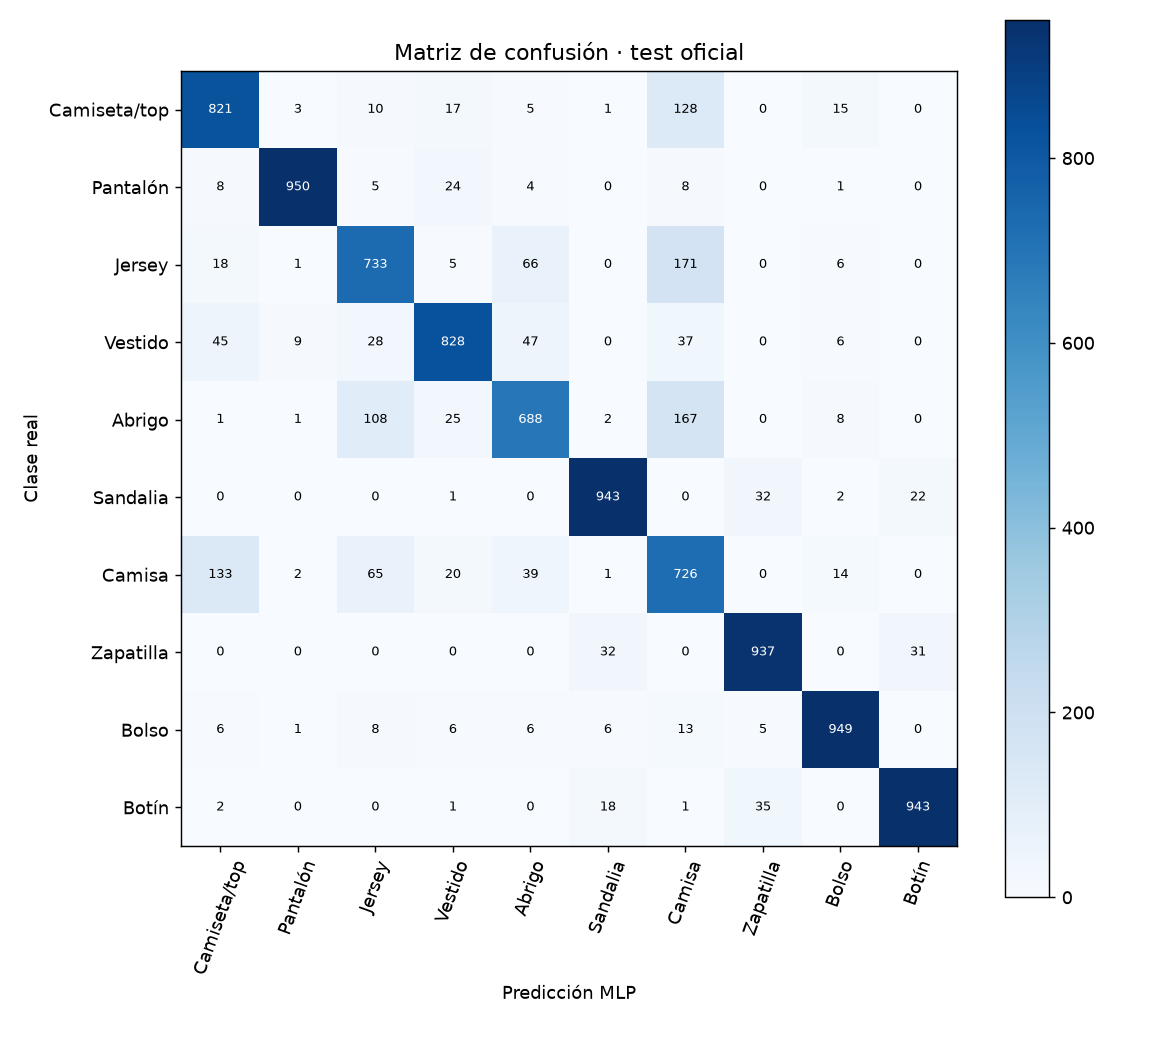

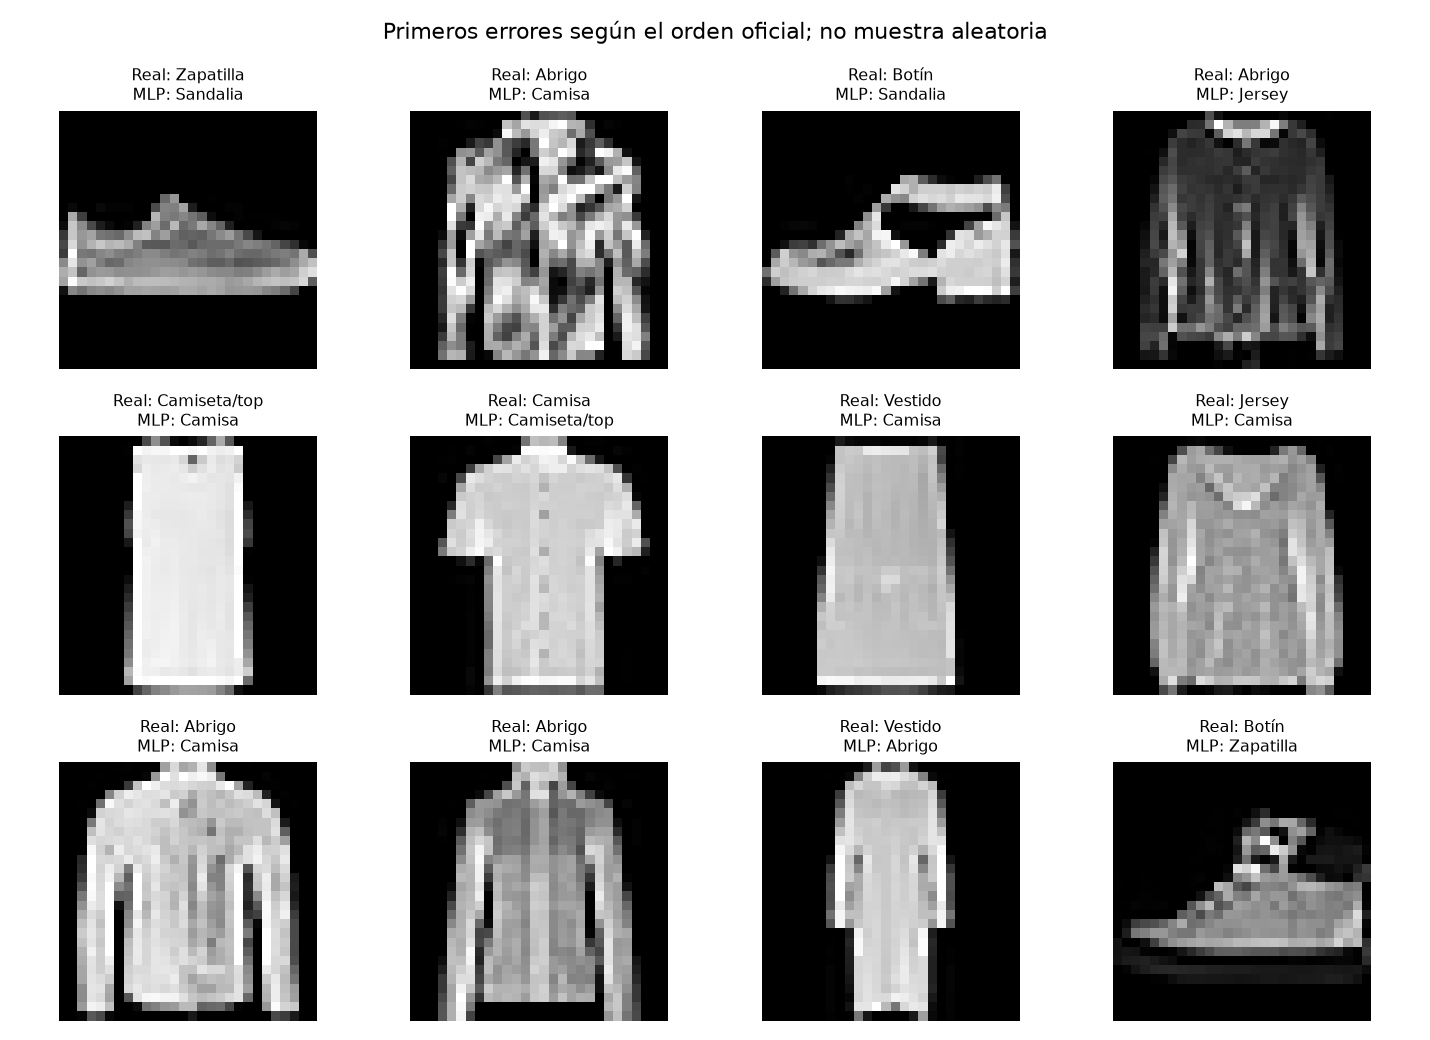

In [2]:
from fashion_mnist_classification.flow import run_stage
metrics, comment = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comment))
from fashion_mnist_classification.presentation import display_evaluation
display_evaluation(PROJECT_ROOT, metrics)


## Alertas e informe

Revisa la descripción y acción sugerida de cada aviso.


In [3]:
mostrar_alertas(PROJECT_ROOT/"reports/alertas/05_evaluacion.json")
from fashion_mnist_classification.informe import generar_informe
informe = generar_informe(PROJECT_ROOT)
display(Markdown("[Informe integral](../reports/informe_final/informe_final.md)"))


[Informe integral](../reports/informe_final/informe_final.md)